# Análise dos clusters
Análise descritiva dos clusters conforme trajetória de mobilidade habitacional

In [1]:
import pandas as pd
import geopandas as gpd

from datetime import datetime, timedelta
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
gdf = gpd.read_parquet('clusters/origem_deslocamentos_clusterizados.parquet')
df_desloc = pd.read_parquet('deslocamentos.parquet')

gdf = gdf.merge(df_desloc[[i for i in df_desloc.columns if i not in gdf.columns]+['id_mudanca']],
                on='id_mudanca', how='left')

In [ ]:
plt.rcParams['font.family'] = ['Fira Sans']

def plotar_gantt(df, col_row_name, col_inicio, col_fim, cluster, date_threshold=None, symbol_size=6):
    if date_threshold:
        colors = ['#013e5b' if row[col_inicio] <= date_threshold <= row[col_fim] else '#a1bfcd' for _, row in df.iterrows()]
    else:
        colors = ['#013e5b'] * len(df)

    fig, ax = plt.subplots(figsize=(10, 3+0.1*len(df)))

    # Posições no eixo Y e rótulos
    y_pos = range(len(df))
    y_labels = (
        df[col_row_name]
        if col_row_name in df.columns
        else [f'Linha {i+1}' for i in range(len(df))]
    )

    # Desenha as barras horizontais representando o intervalo (data_inicio -> data_fim)
    ax.hlines(
        y=y_pos,
        xmin=df[col_inicio],
        xmax=df[col_fim],
        color=colors,
        linewidth=6,
        alpha=1,
        label='Intervalo entre\nendereços diferentes',
        capstyle ='round'
    )
    if date_threshold:
        ax.vlines(
            x=date_threshold,
            ymin=-2,
            ymax=len(df),
            color='#e3dfd8',
            linewidth=6,
            capstyle ='round',
            zorder=-1)
        ax.hlines(
            y=-2,
            xmin=date_threshold-timedelta(days=5),
            xmax=date_threshold+timedelta(days=5),
            color='#a01c08',
            linewidth=10,
            capstyle ='round',
            label='Marco de remoção',
            zorder=1)
        ax.annotate(
            date_threshold.strftime('%d/%m/%Y'),
            xy=(date_threshold, -2),
            xytext=(date_threshold, -3.1),
            fontweight='bold',
            va='center',
            ha='center',
            fontsize=10,
            color='#a01c08',
            fontfamily='Work Sans'
        )

    # Ajustes de eixos e formatação
    ax.set_yticks(y_pos)
    ax.set_yticklabels(y_labels)
    ax.invert_yaxis()  # Inverte para que a primeira linha fique no topo

    # Formatação do eixo de datas
    ax.xaxis_date()
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    fig.autofmt_xdate()

    # Títulos e legenda
    ax.set_xlabel(None)
    ax.tick_params("x", rotation=0, labeltop=True, labelbottom=False, bottom=False, labelsize=12, labelfontfamily='Work Sans')
    ax.get_yaxis().set_visible(False)
    ax.yaxis.set_ticks([])  # Remove os ticks do eixo Y|
    ax.legend(loc='best', ncol=1, frameon=True, facecolor='white', edgecolor='white', fontsize=10, framealpha=0.7)
    ax.grid(True, axis='x', linestyle='--', color='#000000')
    [ax.spines[i].set_visible(False) for i in ('left', 'top', 'right', 'bottom')]
    ax.set_title(f'cluster #{cluster}', fontsize=10, pad=20, fontfamily='Fira Code', x=1, y=-0.08, ha='right')

    plt.tight_layout()
    plt.show()

    ########### PLOTAR VIOLINO DE DATAS ###########

    datas_expandidas = []
    for _, row in df.iterrows():
        datas_intervalo = pd.date_range(
            row[col_inicio], row[col_fim], freq='D'
        )
        datas_expandidas.extend(datas_intervalo)

    df_datas = pd.DataFrame({'data': datas_expandidas})

    # Converter para numérico para permitir que o Seaborn/Matplotlib plote no eixo X contínuo
    df_datas['data_num'] = mdates.date2num(df_datas['data'])

    fig, ax = plt.subplots(figsize=(10, 3))

    # Violin plot disposta no eixo X (orientação horizontal ao longo das datas)
    sns.violinplot(
        x=df_datas['data_num'],
        ax=ax,
        color="#013e5b",
        inner=None,
        linewidth=0.01,
        cut=0,  # Garante que o violino não se estenda além da menor/maior data
    )

    if date_threshold:
        ymin, ymax = ax.get_ylim()
        ax.vlines(
            x=date_threshold,
            ymin=ymin,
            ymax=ymax,
            color='#e3dfd8',
            linewidth=6,
            capstyle ='round',
            zorder=-1)
        ax.hlines(
            y=ymax,
            xmin=date_threshold-timedelta(days=5),
            xmax=date_threshold+timedelta(days=5),
            color='#a01c08',
            linewidth=10,
            capstyle ='round',
            label='Marco de remoção',
            zorder=1)
        ax.annotate(
            date_threshold.strftime('%d/%m/%Y'),
            xy=(date_threshold, ymax),
            xytext=(date_threshold, ymax-0.08),
            fontweight='bold',
            va='center',
            ha='center',
            fontsize=10,
            color='#a01c08',
            fontfamily='Work Sans'
        )

    # Formatar o eixo X para exibir as datas originais
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    fig.autofmt_xdate()

    # Rotulagem e estética
    ax.set_xlabel(None)
    ax.tick_params("x", rotation=0, labeltop=True, labelbottom=False, bottom=False, labelsize=12, labelfontfamily='Work Sans')
    ax.get_yaxis().set_visible(False)
    ax.yaxis.set_ticks([])  # Remove os ticks do eixo Y
    ax.grid(True, axis='x', linestyle='--', color='#000000')
    [ax.spines[i].set_visible(False) for i in ('left', 'top', 'right', 'bottom')]
    ax.set_title(f'cluster #{cluster}', fontsize=10, pad=20, fontfamily='Fira Code', x=1, y=-0.2, ha='right')

    plt.tight_layout()
    plt.show()


    ########### PLOTAR VIOLINO DE DISTANCIAS ###########
    dic_situacao = {
        (False, False): 'Fora do aluguel',
        (True, False): 'Saiu do aluguel',
        (False, True): 'Entrou no aluguel',
        (True, True): 'Continua no aluguel',
    }
    situacao = df.apply(lambda x: (x['VL_DESP_ALUGUEL_FAM']>0, x['VL_DESP_ALUGUEL_FAM_pos']>0), axis=1)
    situacao = situacao.apply(lambda x: dic_situacao.get(x, 'Desconhecido'))
    cores_situacao = {
        'Fora do aluguel': "#95ccda",
        'Saiu do aluguel': "#157e72",
        'Continua no aluguel': "#f0a94c",
        'Entrou no aluguel': "#df5e22",
    }

    despesas = df.apply(lambda x: 'Aumento das\ndespesas' if x['tt_despesas_pos']*1.05>x['tt_despesas'] else 'Redução ou\nmanutenção\ndas despesas', axis=1)

    fig, ax = plt.subplots(figsize=(10, 5))
    
    # Violin plot disposta no eixo X (orientação horizontal ao longo das datas)
    sns.swarmplot(
        x=df['distancia']/1000,
        y=despesas,
        ax=ax,
        linewidth=0.01,
        hue=situacao,
        hue_order=cores_situacao.keys(),
        order=['Aumento das\ndespesas', 'Redução ou\nmanutenção\ndas despesas'],
        palette=cores_situacao,
        size=symbol_size - len(df)/100,  # Ajusta o tamanho dos pontos com base no número de registros
        dodge=False,  # Evita sobreposição de pontos
    )

    # Rotulagem e estética
    ax.set_xlim(-1, df['distancia'].max()/1000 + 1)
    ax.set_xlabel('Distância entre endereços (km)', fontsize=11, fontfamily='Work Sans', color='#777777')
    ax.set_ylabel(None)
    ax.tick_params("x", rotation=0, labeltop=True, labelbottom=False, bottom=False, labelsize=12, labelfontfamily='Work Sans', labelcolor='#777777')
    ax.grid(True, axis='x', linestyle='-', color='#cccccc')
    ax.legend(loc='best', ncol=1, frameon=True, facecolor='white', edgecolor='white', fontsize=10, framealpha=0.7)
    [ax.spines[i].set_visible(False) for i in ('left', 'top', 'right', 'bottom')]
    ax.set_title(f'cluster #{cluster}', fontsize=10, pad=20, fontfamily='Fira Code', x=1, y=-0.2, ha='right')

    plt.tight_layout()
    plt.show()

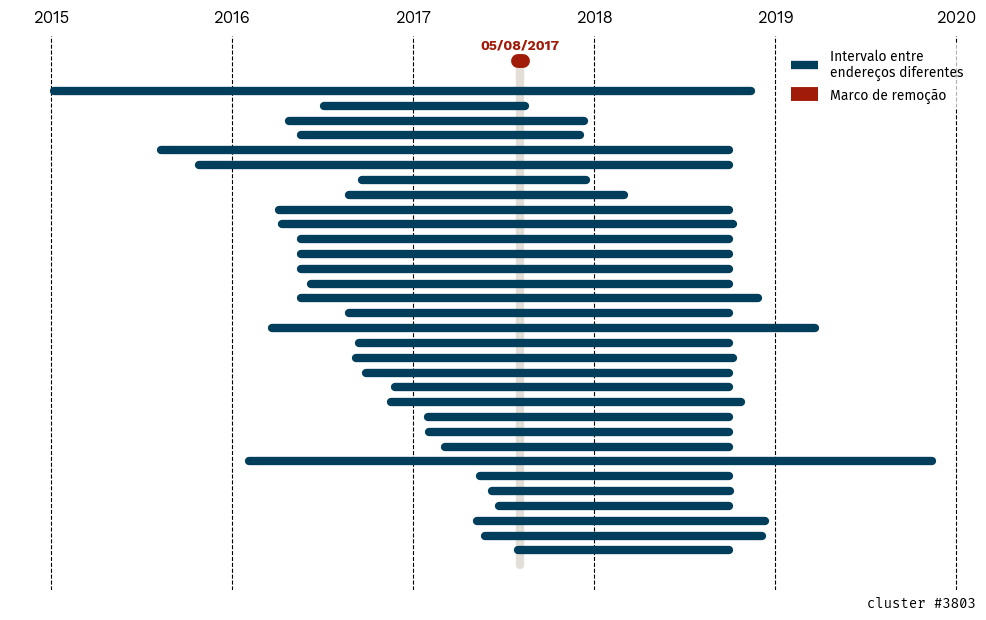

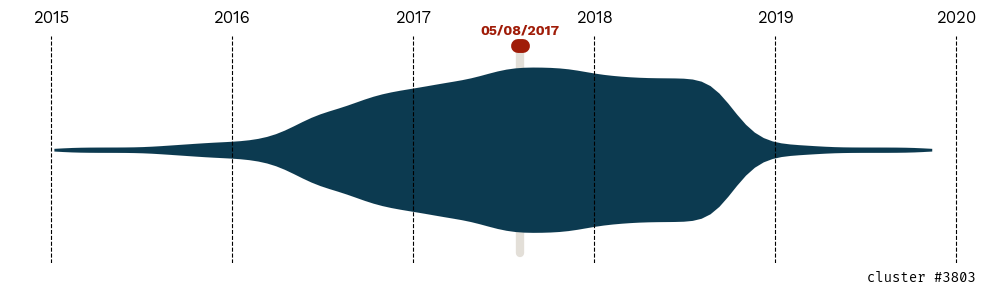

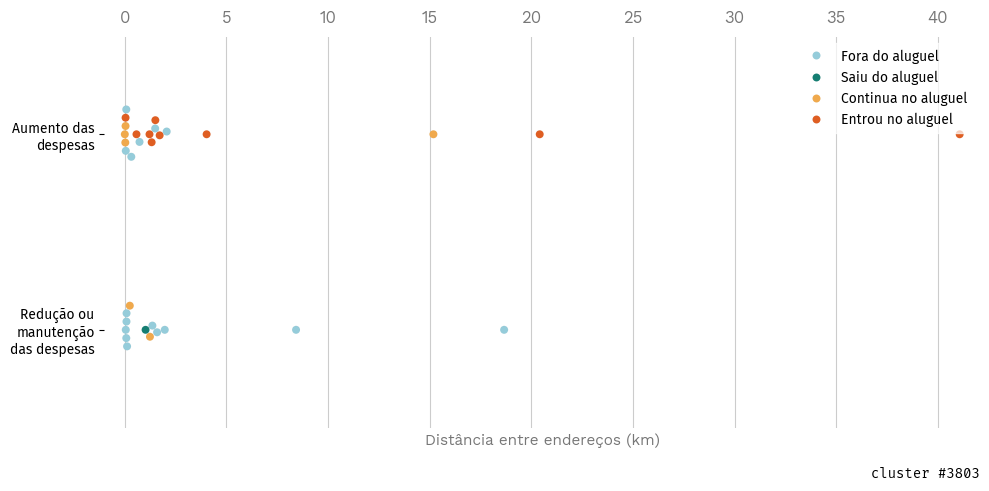

In [ ]:
id_cluster = 3803
plotar_gantt(gdf.query(f'cluster_60m_6M == {id_cluster}').sort_values(by='data_media'), 'CO_FAMILIAR_FAM', 'DT_ATUALIZACAO_FAM', 'DT_ATUALIZACAO_FAM_pos', id_cluster, date_threshold=datetime(2017, 8, 5))

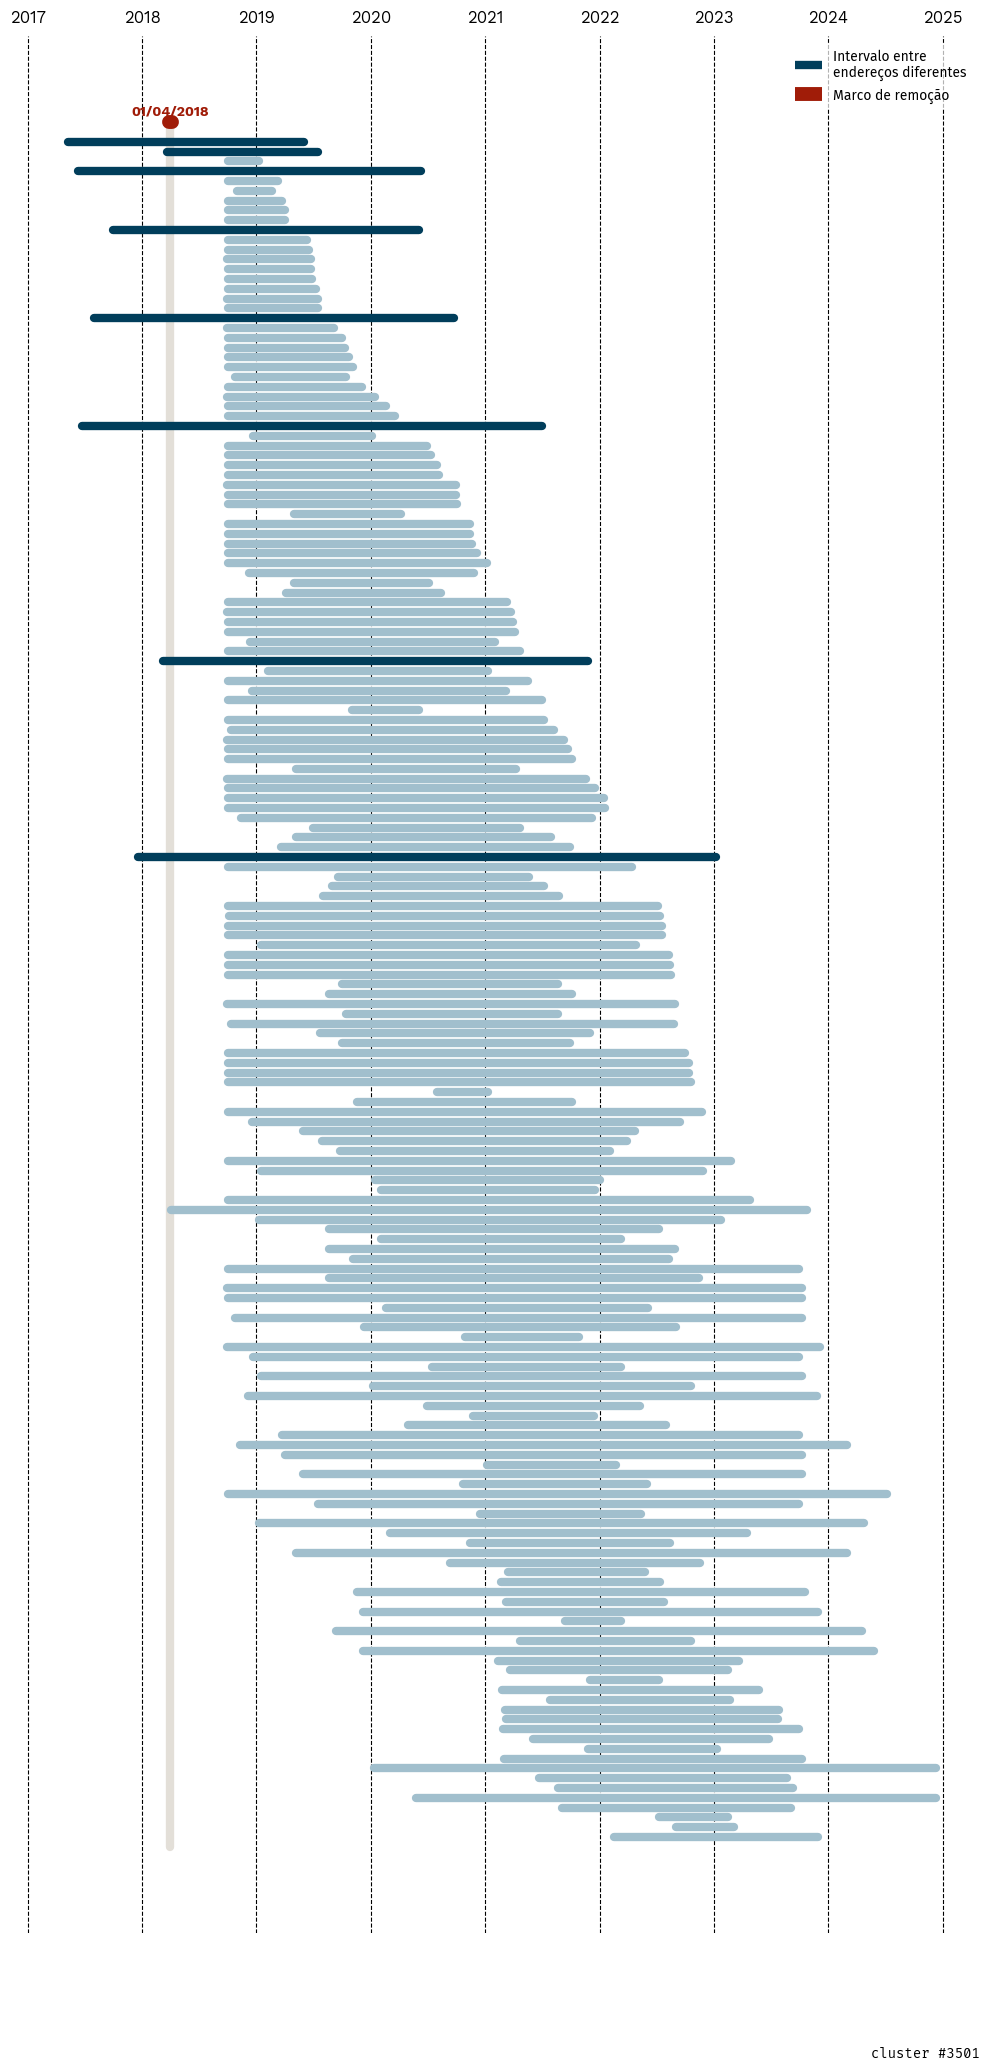

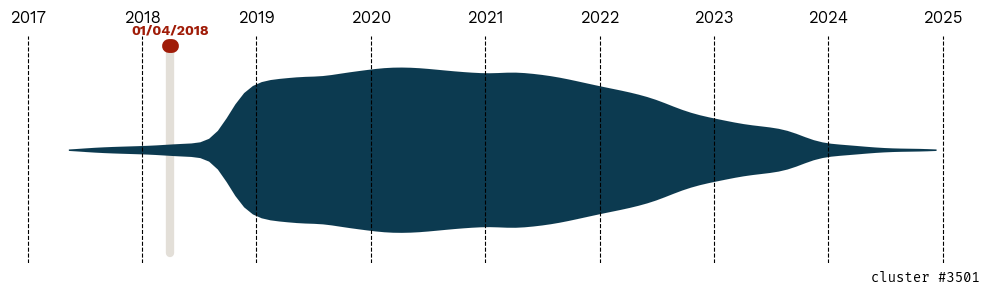

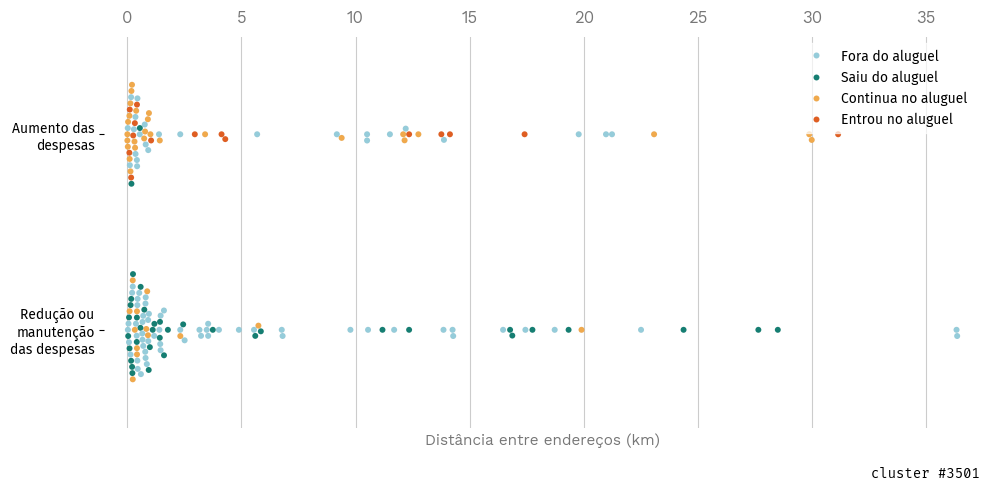

In [ ]:
id_cluster = 3501
plotar_gantt(gdf.query(f'cluster_60m_6M == {id_cluster}').sort_values(by='data_media'), 'CO_FAMILIAR_FAM', 'DT_ATUALIZACAO_FAM', 'DT_ATUALIZACAO_FAM_pos', id_cluster, date_threshold=datetime(2018, 4, 1))

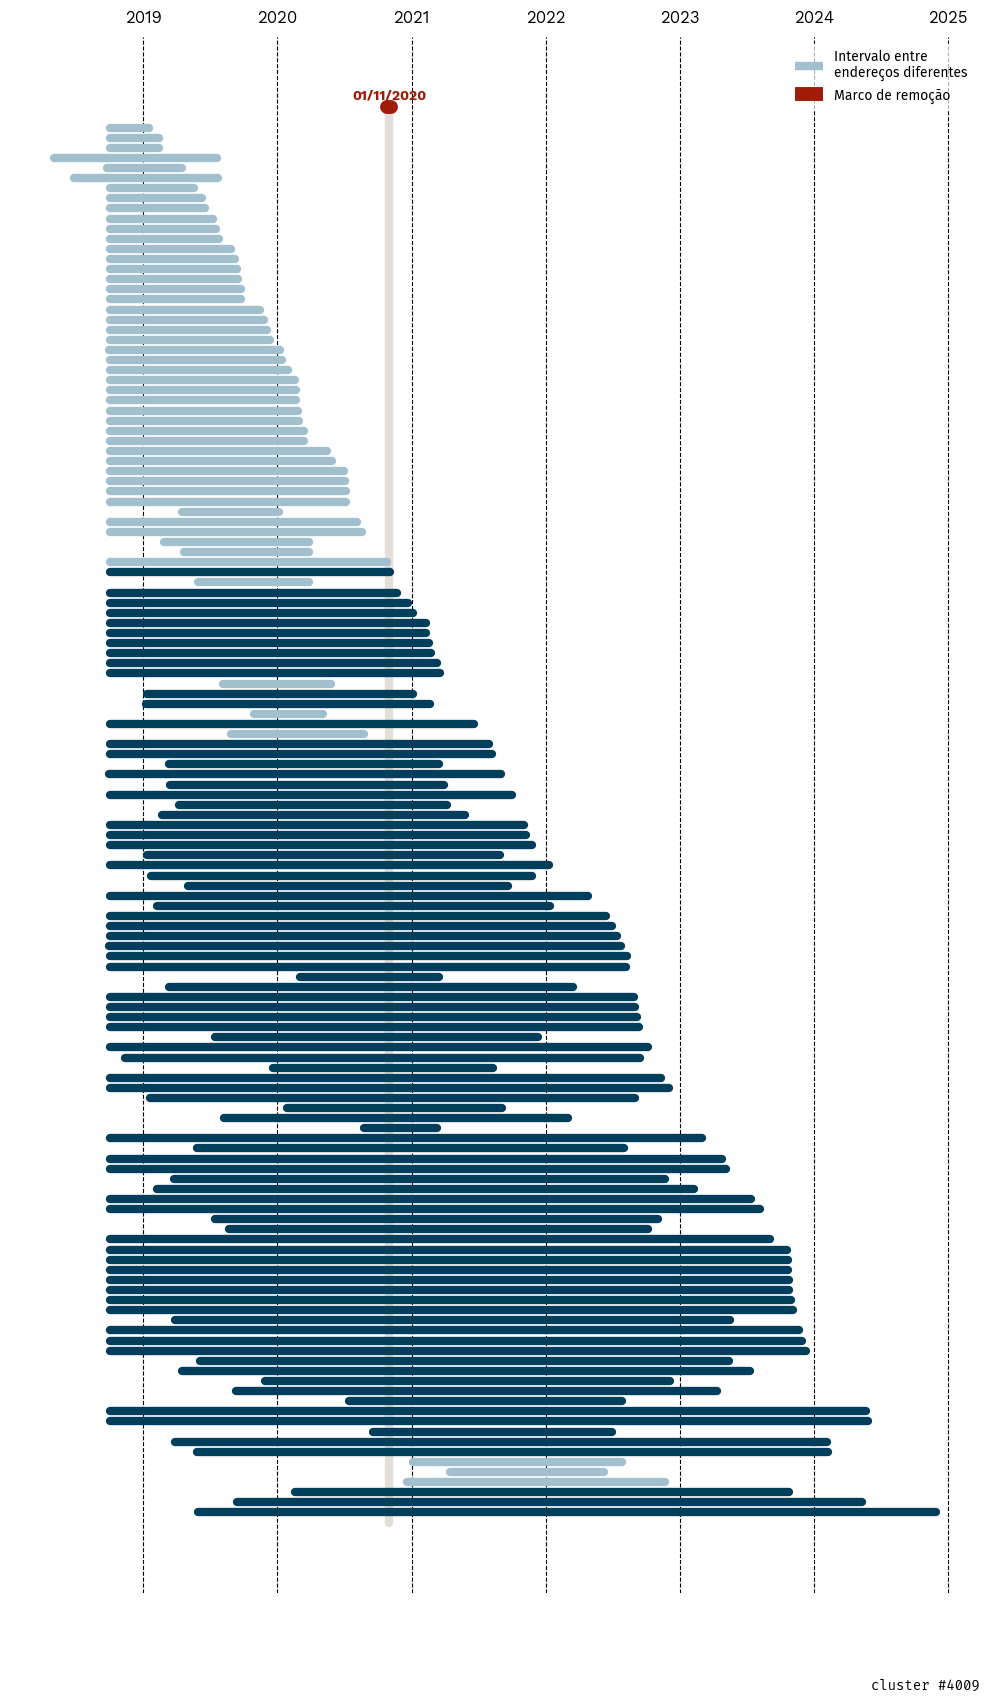

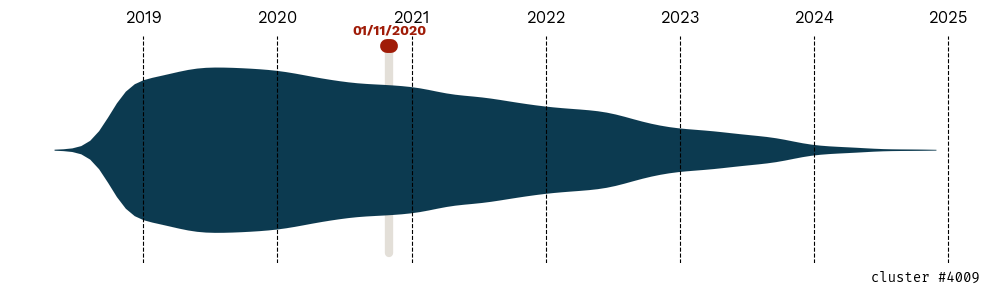

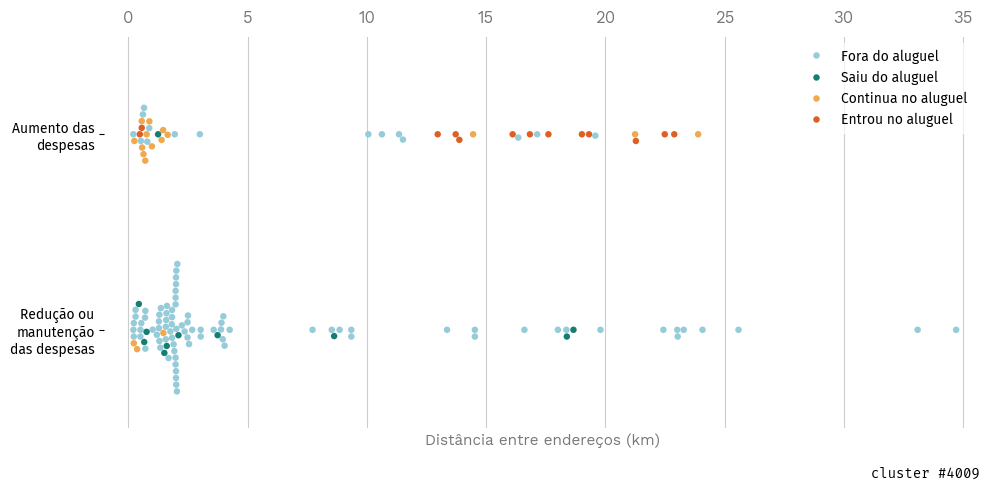

In [ ]:
id_cluster = 4009
plotar_gantt(gdf.query(f'cluster_60m_6M == {id_cluster}').sort_values(by='data_media'), 'CO_FAMILIAR_FAM', 'DT_ATUALIZACAO_FAM', 'DT_ATUALIZACAO_FAM_pos', id_cluster, date_threshold=datetime(2020, 11, 1))

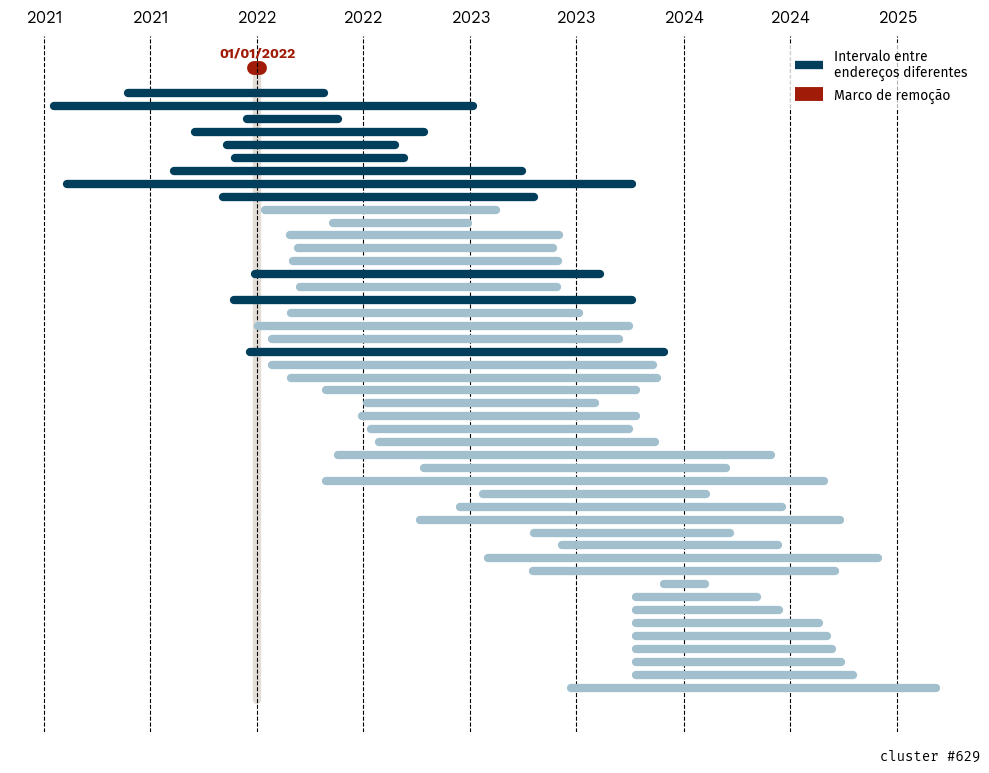

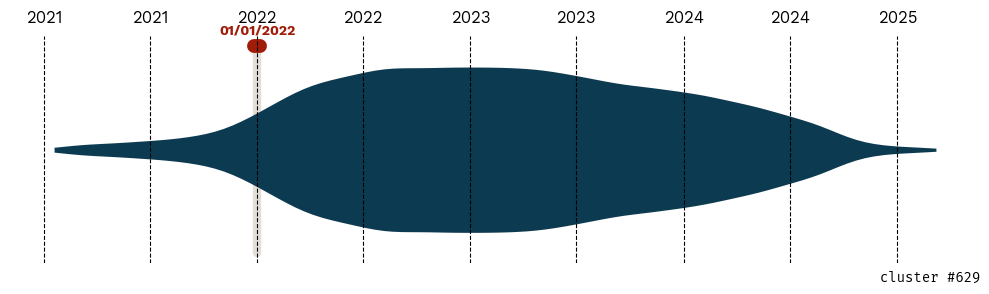

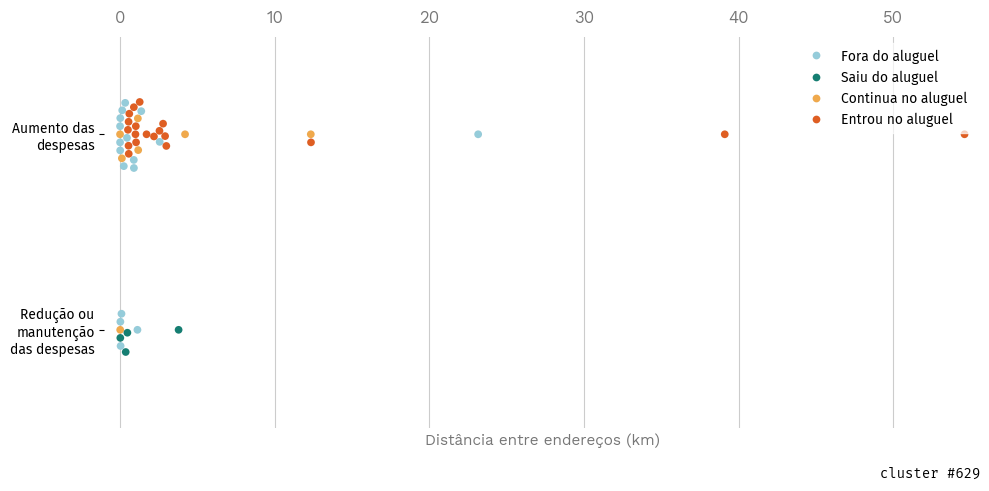

In [ ]:
id_cluster = 629
plotar_gantt(gdf.query(f'cluster_60m_6M == {id_cluster}').sort_values(by='data_media'), 'CO_FAMILIAR_FAM', 'DT_ATUALIZACAO_FAM', 'DT_ATUALIZACAO_FAM_pos', id_cluster, date_threshold=datetime(2022, 1, 1))

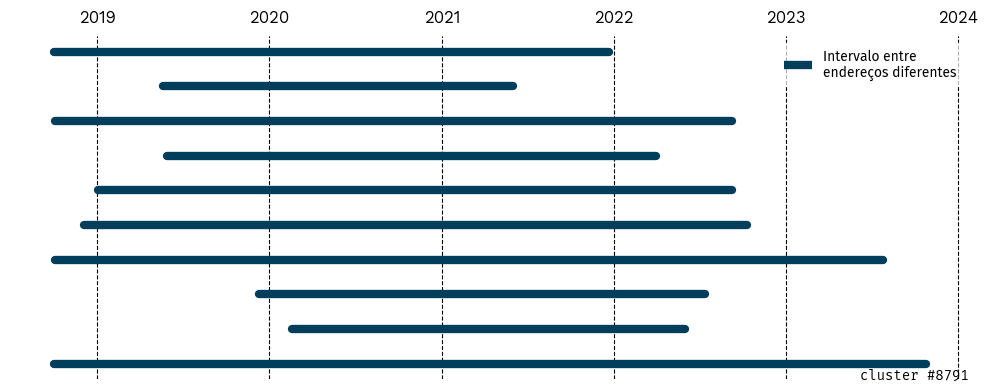

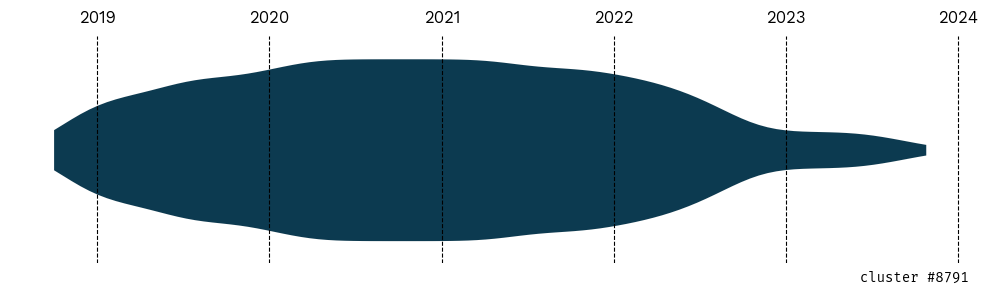

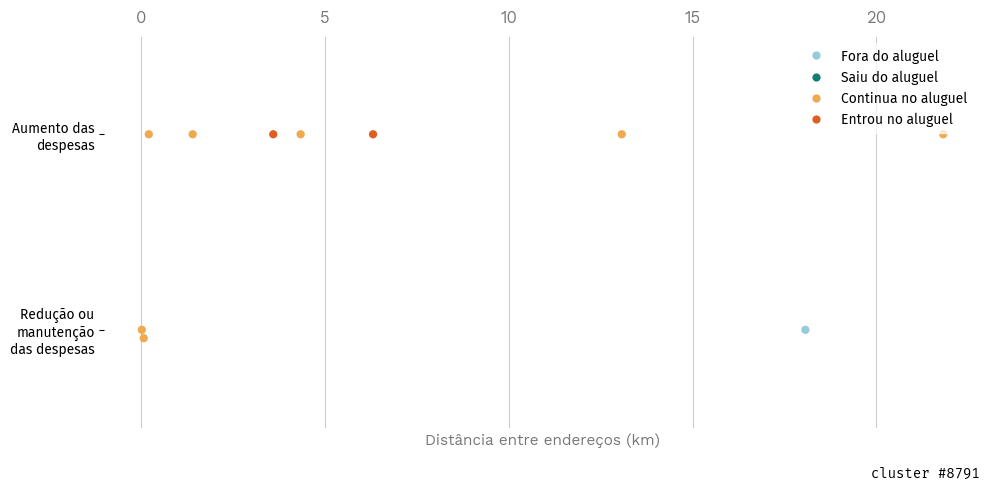

In [ ]:
id_cluster = 8791
plotar_gantt(gdf.query(f'cluster_60m_6M == {id_cluster}').sort_values(by='data_media'), 'CO_FAMILIAR_FAM', 'DT_ATUALIZACAO_FAM', 'DT_ATUALIZACAO_FAM_pos', id_cluster)

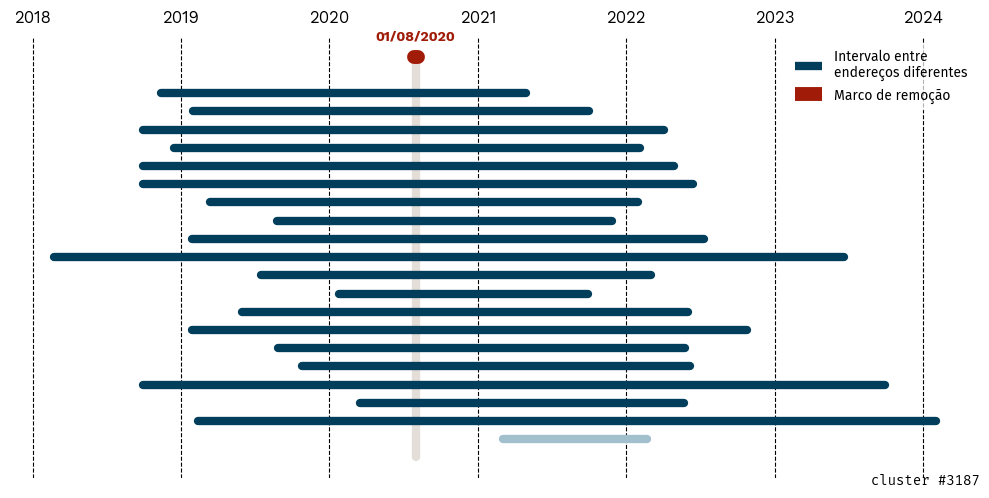

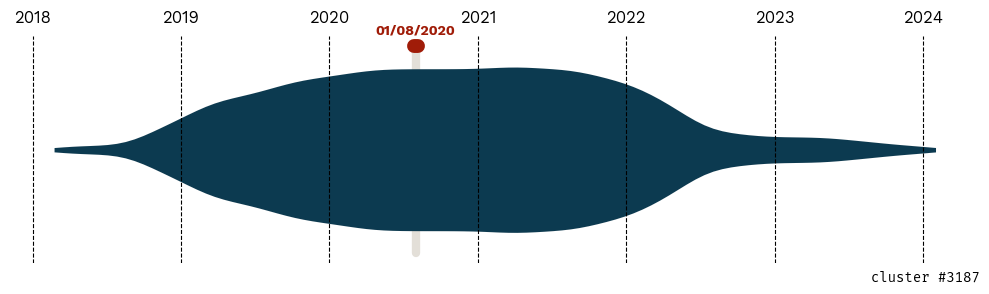

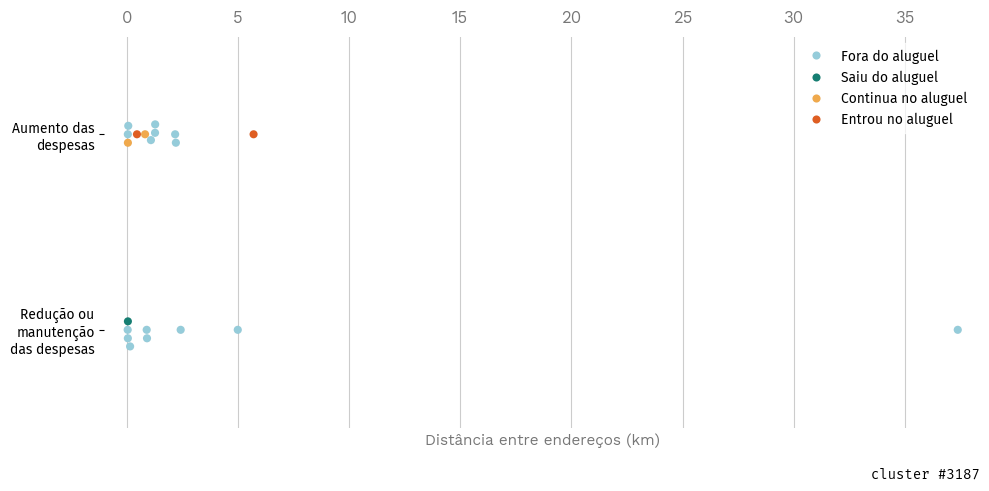

In [ ]:
id_cluster = 3187
plotar_gantt(gdf.query(f'cluster_60m_6M == {id_cluster}').sort_values(by='data_media'), 'CO_FAMILIAR_FAM', 'DT_ATUALIZACAO_FAM', 'DT_ATUALIZACAO_FAM_pos', cluster=id_cluster, date_threshold=datetime(2020, 8, 1))

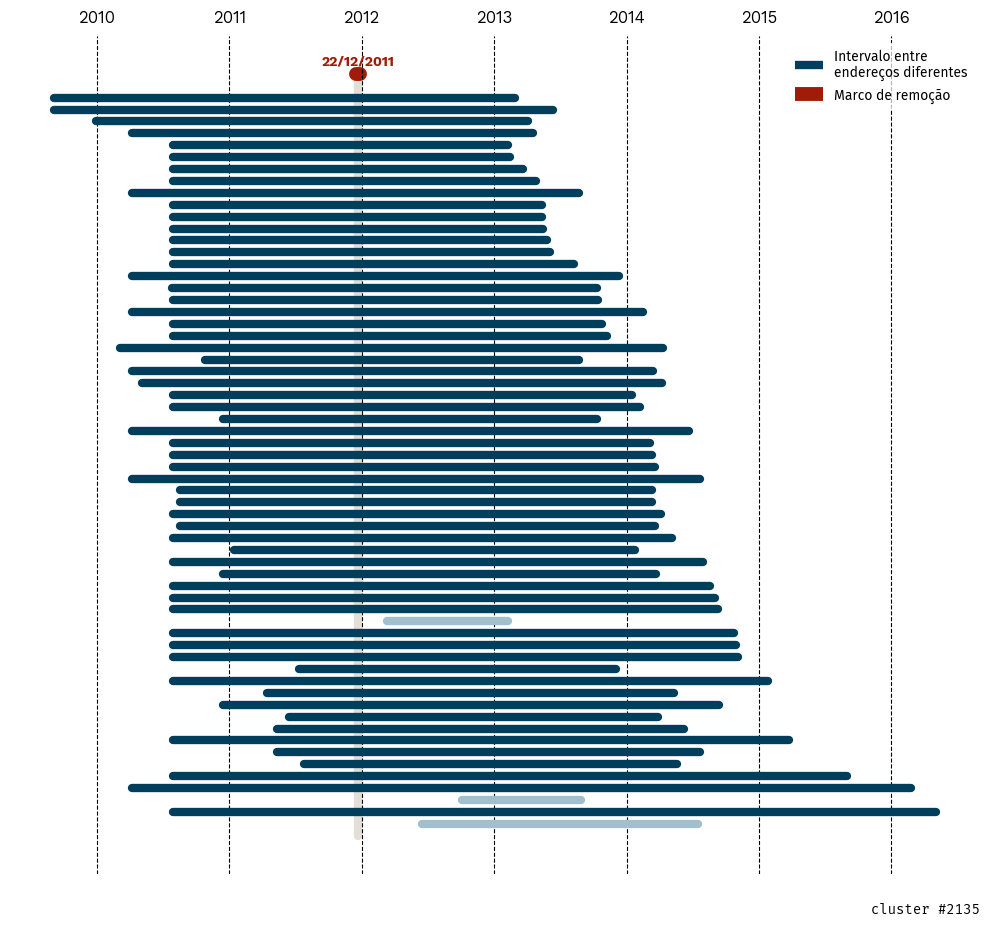

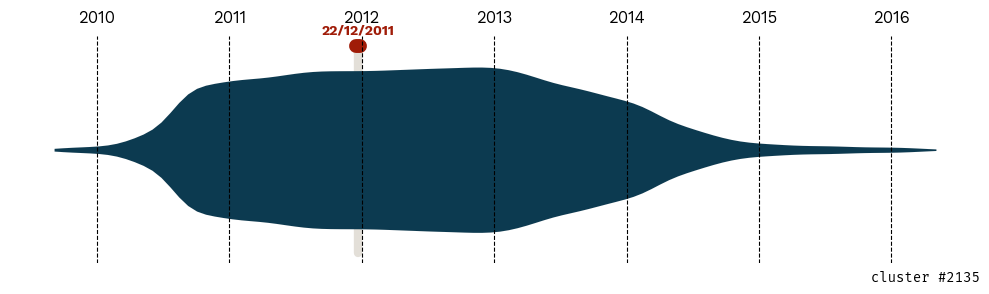

c:\Users\Pedro\anaconda3\envs\geo\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 21.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


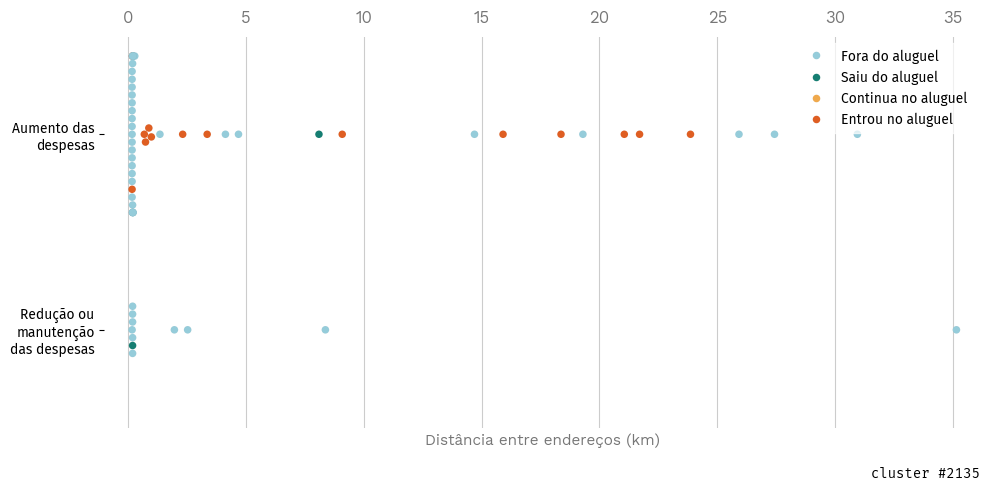

In [ ]:
id_cluster = 2135
plotar_gantt(gdf.query(f'cluster_60m_6M == {id_cluster}').sort_values(by='data_media'), 'CO_FAMILIAR_FAM', 'DT_ATUALIZACAO_FAM', 'DT_ATUALIZACAO_FAM_pos', cluster=id_cluster, date_threshold=datetime(2011, 12, 22))

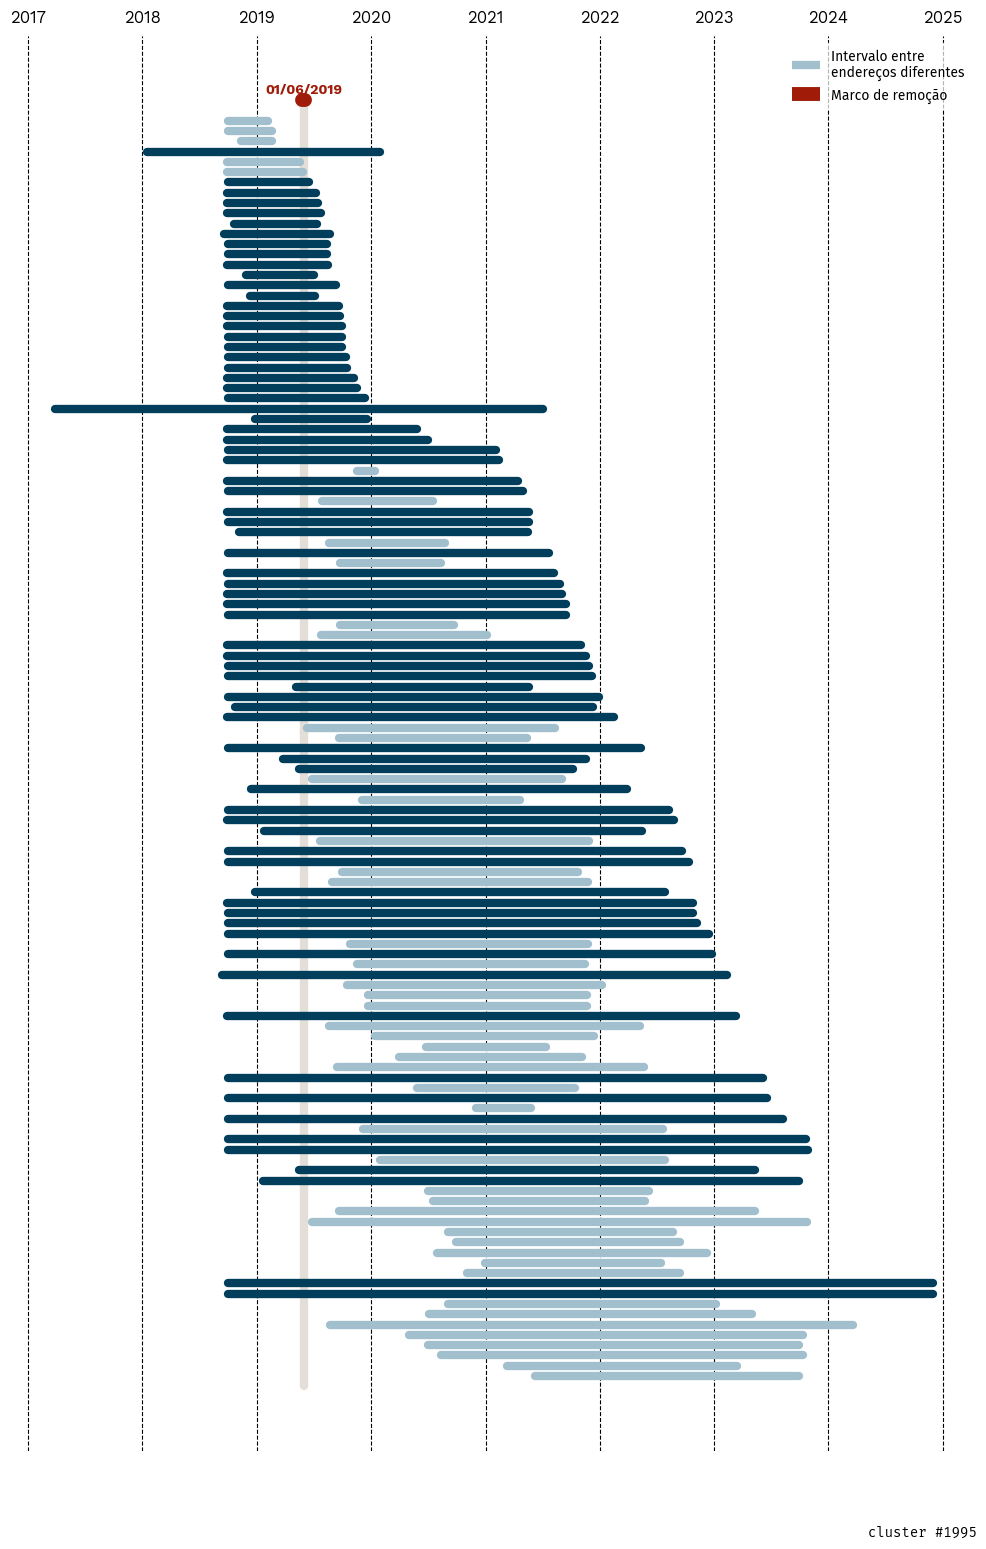

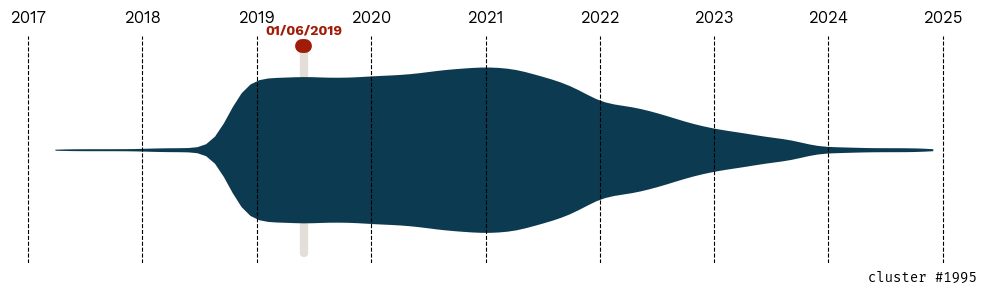

c:\Users\Pedro\anaconda3\envs\geo\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 10.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


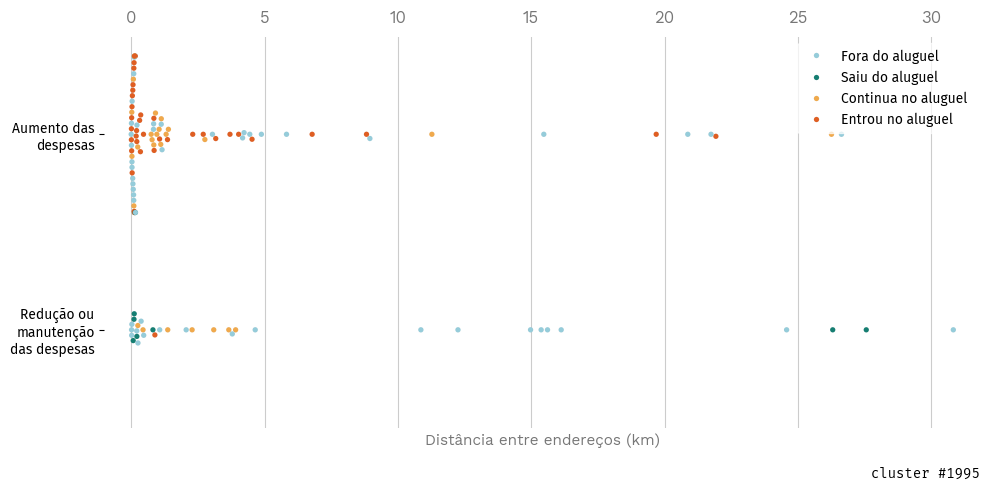

In [ ]:
id_cluster = 1995
plotar_gantt(gdf.query(f'cluster_60m_6M == {id_cluster}').sort_values(by='data_media'), 'CO_FAMILIAR_FAM', 'DT_ATUALIZACAO_FAM', 'DT_ATUALIZACAO_FAM_pos', 
             cluster=id_cluster, 
             date_threshold=datetime(2019, 6, 1),
             symbol_size=5)

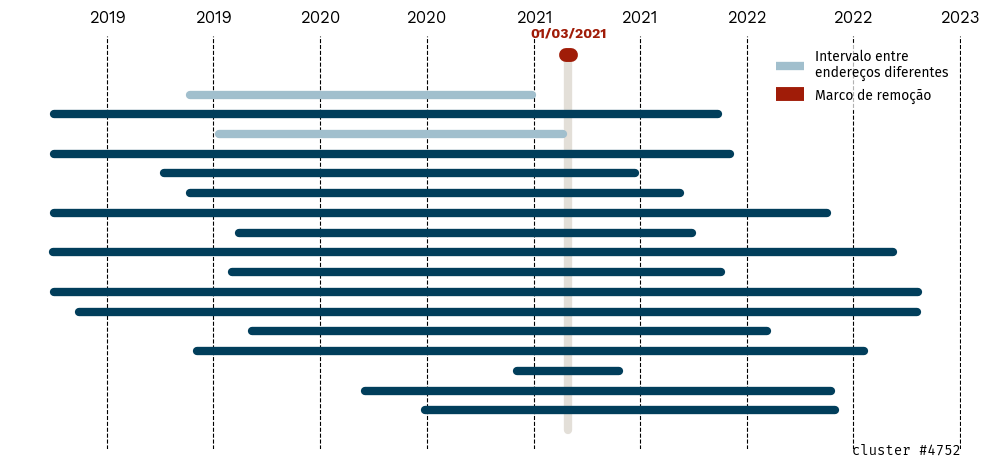

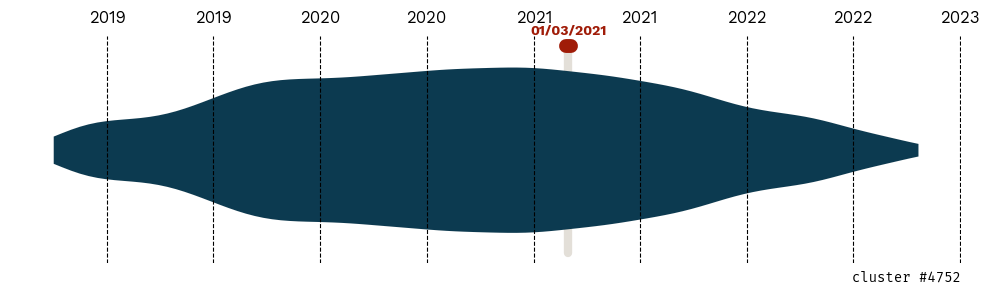

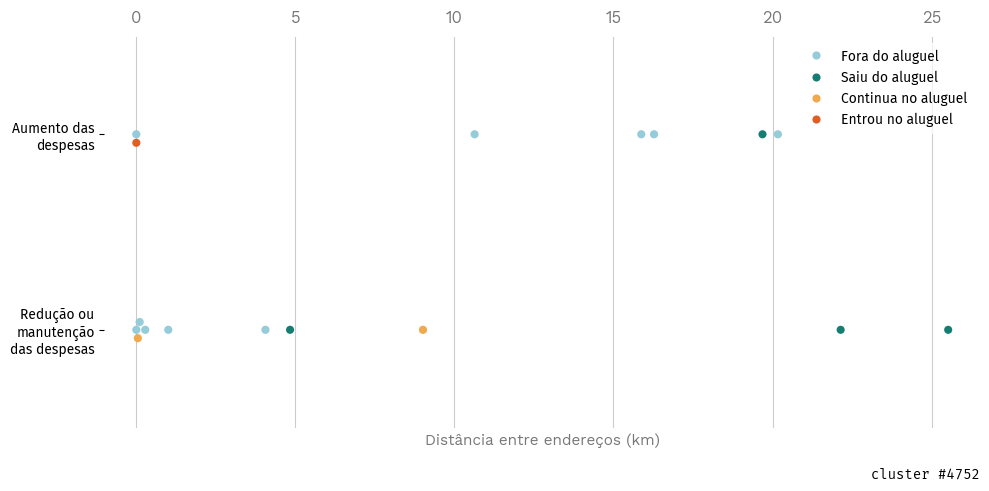

In [ ]:
id_cluster = 4752
plotar_gantt(gdf.query(f'cluster_60m_6M == {id_cluster}').sort_values(by='data_media'), 'CO_FAMILIAR_FAM', 'DT_ATUALIZACAO_FAM', 'DT_ATUALIZACAO_FAM_pos', 
             cluster=id_cluster, 
             date_threshold=datetime(2021, 3, 1))

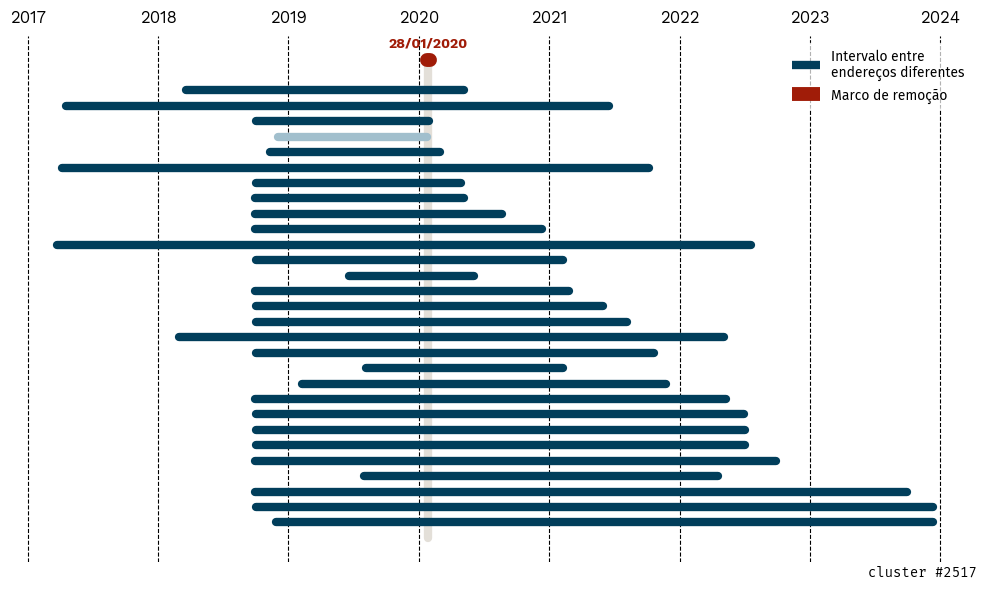

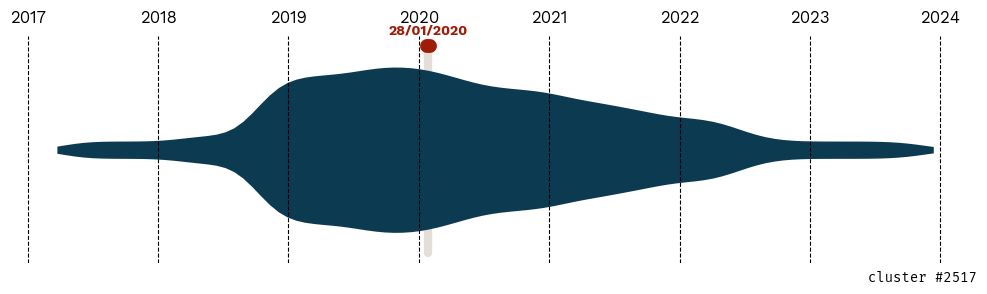

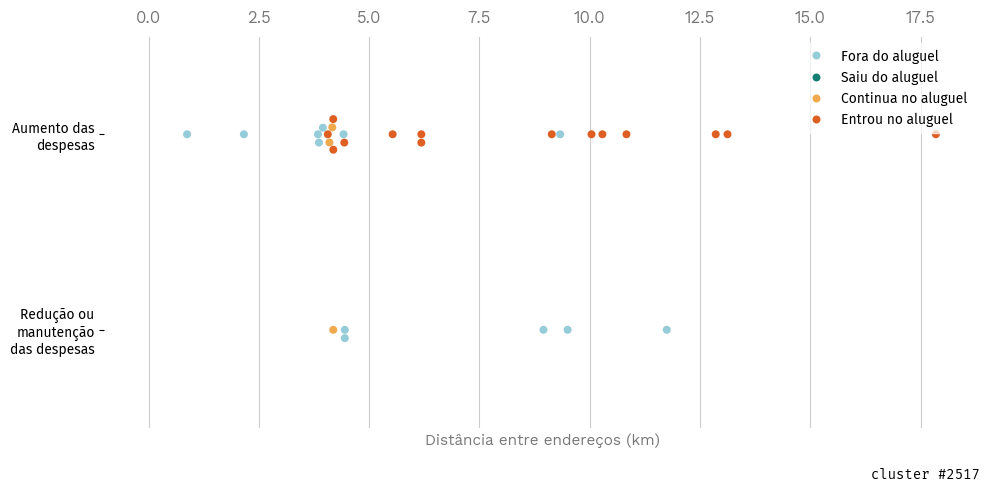

In [ ]:
id_cluster = 2517
plotar_gantt(gdf.query(f'cluster_60m_6M == {id_cluster}').sort_values(by='data_media'), 'CO_FAMILIAR_FAM', 'DT_ATUALIZACAO_FAM', 'DT_ATUALIZACAO_FAM_pos', 
             cluster=id_cluster, 
             date_threshold=datetime(2020, 1, 28),)

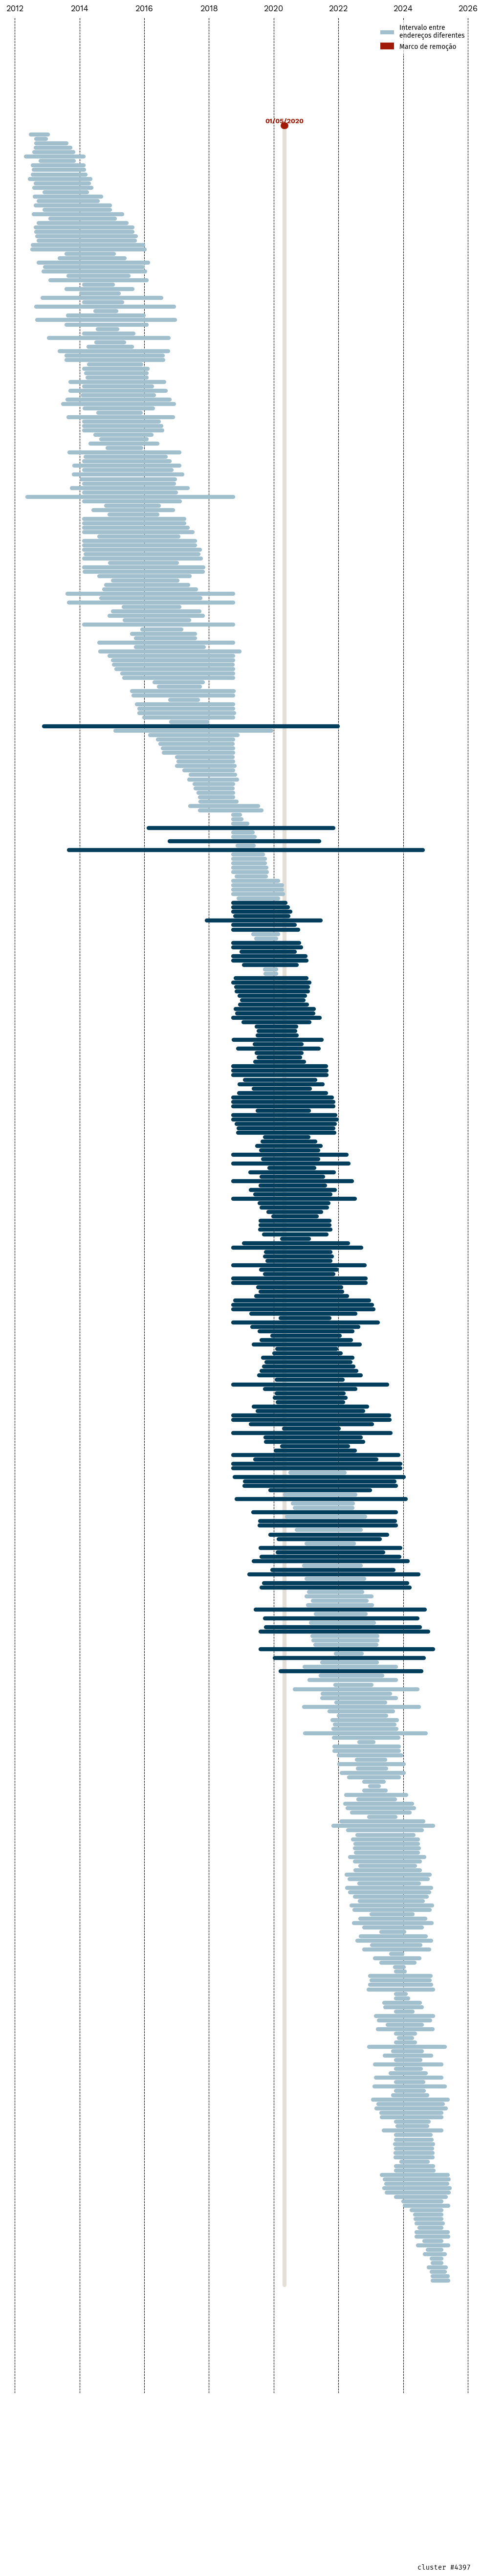

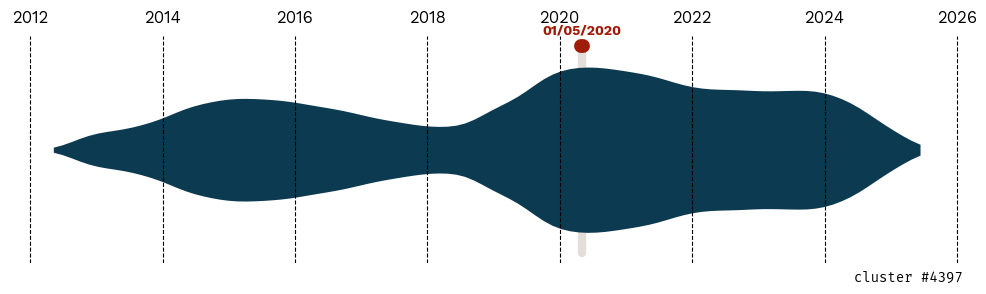

c:\Users\Pedro\anaconda3\envs\geo\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 10.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


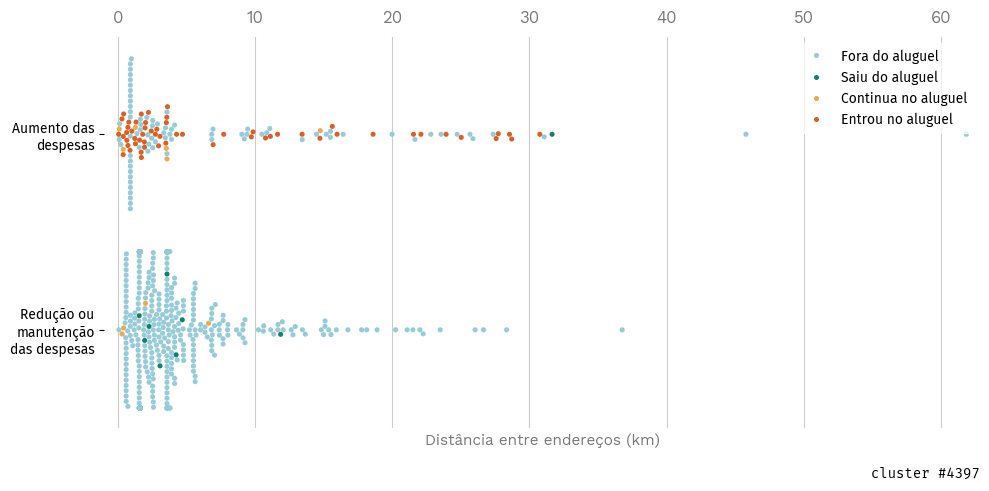

In [ ]:
id_cluster = 4397
plotar_gantt(gdf.query(f'cluster_60m_6M == {id_cluster}').sort_values(by='data_media'), 'CO_FAMILIAR_FAM', 'DT_ATUALIZACAO_FAM', 'DT_ATUALIZACAO_FAM_pos', 
             cluster=id_cluster, 
             date_threshold=datetime(2020, 5, 1),
             symbol_size=8.5)